# Per-reason SVM tuning, pseudo-label reliability and local specialists

The user requested all three remaining refinements and reported a new Kaggle leader in the **0.93xx** range. The exact leaderboard score was not supplied. Kaggle and local validation remain separate evaluations; our model's Kaggle score is unmeasured.

The starting model scored **0.912393 validation sample-wise F1**. After these tests, the current saved best scores **0.912393**. All 78 validation rows remain excluded from fitting. The final train-plus-validation refit remains deferred.

The raw screen contained 60 configurations: six nested per-reason tuning policies, 24 reliability-weighted variants plus six uniform-weight controls, and 24 local specialist variants. Predictions from each were evaluated under four thresholds and four label scopes, using training data only.

In [1]:
from pathlib import Path
import json,pandas as pd,numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
summary=json.loads((root/'experiments/phase25-summary.json').read_text())
summary

{'raw_configurations': 60,
 'families': {'label_tuned_ssl': 6, 'reliable_ssl': 30, 'local_ssl': 24},
 'uniform_reliability_controls': 6,
 'inner_parameter_recipes': 9,
 'inner_folds': 5,
 'decision_policies_per_raw_configuration': 16,
 'repeat_seeds': [20261119, 20261120, 20261121],
 'validation_candidates': 5,
 'baseline_validation_f1': 0.9123931623931625,
 'baseline_matched_cv': 0.9132342533616419,
 'results': [{'name': 'phase25_label_tuned_ssl',
   'cv': 0.9186128803963198,
   'validation': 0.8931623931623932,
   'macro': 0.7665512265512266},
  {'name': 'phase25_reliable_ssl',
   'cv': 0.9150743099787685,
   'validation': 0.8888888888888891,
   'macro': 0.7645714285714286},
  {'name': 'phase25_local_ssl',
   'cv': 0.9200283085633404,
   'validation': 0.9059829059829061,
   'macro': 0.7713531353135313},
  {'name': 'phase25_control_label_tuned_ssl',
   'cv': 0.9186128803963198,
   'validation': 0.9102564102564102,
   'macro': 0.7963131313131313},
  {'name': 'phase25_control_reliable_s

## Per-reason SVM settings

Every outer fold runs its own five-fold grouped inner CV over nine SVM recipes. The recipe grid varies regularization C, RBF gamma and pseudo-label weight near the earlier best configuration. Each reason can select a different recipe. The screen compares independent binary-F1 selection and coordinate selection targeting sample-wise F1, with penalties of 0, 0.005 or 0.02 for departing from the common baseline.

Inner preprocessing and pseudo-label updates exclude inner held-out rows and their masked embedding duplicates. The selected recipes then fit the outer training rows. This tests a complete tuning procedure; a single set of globally optimized label parameters is not reused across outer validation folds. Original gold labels are never changed.

The final label scopes considered are all reasons, Other alone, Recruitment/Other, and Safety/Funding/Efficacy. Scoped policies preserve the previous model's decisions for the remaining reasons. Empty combined predictions fall back to that model.

## Reliability-weighted pseudo-labels

The teacher is either a supervised gold-only SVM or the earlier cluster-guided semi-supervised SVM. Five-fold inner OOF predictions train the reliability estimator. The per-reason variant calibrates each reason's signed margin to a class probability. The pooled variant predicts whether a margin's binary decision is correct, using margin magnitude, signed margin and reason indicators across all five tasks.

The full-fold teacher supplies fixed provisional labels for the masked rows. Reliability controls their training weights: max(2r−1, 0) squared, with a minimum reliability cutoff of 0.5 or 0.8. Overall pseudo-label weights are 0.03, 0.1 or 0.3. KMeans cluster agreement further downweights conflicts. Zero-weight pseudo-label rows are removed so they do not influence automatic class-frequency balancing.

The student fits gold labels plus these weighted provisional labels. The calibrator affects training weights; it is not merely a final prediction threshold adjustment. Teacher labels remain fixed during this student fit. Reliability is estimated on the labeled training distribution, so it is not guaranteed to stay calibrated under the later-trial distribution shift.

## Local SVM specialists

KMeans identifies three or six regions using only permitted training embeddings. Each expert retains all gold examples with distance-based weights and uses the 250 masked examples nearest its region center, labeled by the earlier global semi-supervised SVM. Gold weights have a floor to preserve shared information across regions.

Each expert fits five binary SVMs. Its output is blended with global scores at a maximum weight of 0.25 or 0.5, reduced further for reasons with little weighted positive or negative support. Smooth routing averages nearby experts. Regularization C of 0.3/1/3 and gamma of 0.001/0.003 are screened. No query features affect cluster fitting, neighborhood selection or model training.

This tests local decision functions and global sharing. It is distinct from the earlier experiment that changed the distance metric of one global SVM.

## Selection and controls

The initial outer CV uses seed 20261118. Ordinary and robust weighted CV nominate up to two policies from each family. Those policies are frozen and reevaluated on seeds 20261119–20261121. One repeated-CV winner per family is frozen before validation scoring.

Two matched controls keep their selected policy's scope and threshold: one removes per-reason parameter tuning, and one replaces learned reliability weights with uniform pseudo-label weights. No control-specific retuning is performed. The local expert implementation also has an exact numerical zero-blend check against its global model.

All splits group identical reason embeddings. Matching masked duplicates of held-out groups are removed at both inner and outer levels. All validation predictions are saved before labels are read for reporting. The entire historical search remains adaptive; nested tuning and leakage checks do not erase selection bias from repeated validation comparisons.

In [2]:
repeats=json.loads((root/'experiments/phase25-repeat-results.json').read_text())
rows=[dict(family=r['config']['learner']['model'],scope=r['config']['scope'],threshold=r['config']['decision_rule'],mean_cv=r['ordinary_cv'],split_std=r['cv_std'],robust_cv=r['robust_cv'],settings=json.dumps(r['config']['learner'],sort_keys=True)) for r in repeats]
pd.DataFrame(rows)

,family,scope,threshold,mean_cv,split_std,robust_cv,settings
0,label_tuned_ssl,other,t0.65,0.918613,0.008896,0.911363,"{""inner_splits"": 5, ""model"": ""label_tuned_ssl""..."
1,label_tuned_ssl,rare,t0.55,0.908280,0.013079,0.903265,"{""inner_splits"": 5, ""model"": ""label_tuned_ssl""..."
2,reliable_ssl,recruitment_other,t0.65,0.915074,0.009008,0.910117,"{""inner_splits"": 5, ""min_reliability"": 0.5, ""m..."
3,reliable_ssl,recruitment_other,t0.65,0.912951,0.009652,0.909374,"{""inner_splits"": 5, ""min_reliability"": 0.5, ""m..."
4,local_ssl,all,t0.55,0.907997,0.010158,0.902807,"{""C"": 3, ""gamma"": 0.001, ""local_mix"": 0.5, ""mo..."
5,local_ssl,recruitment_other,t0.65,0.920028,0.002002,0.916069,"{""C"": 3, ""gamma"": 0.001, ""local_mix"": 0.25, ""m..."


In [3]:
results=json.loads((root/'experiments/phase25-validation-results.json').read_text())+json.loads((root/'experiments/phase25b-validation-results.json').read_text())
table=pd.DataFrame([dict(candidate=r['name'],cv=r['ordinary_cv'],validation_f1=r['validation']['sample_f1'],macro_f1=r['validation']['macro_f1']) for r in results])
table

,candidate,cv,validation_f1,macro_f1
0,phase25_label_tuned_ssl,0.918613,0.893162,0.766551
1,phase25_reliable_ssl,0.915074,0.888889,0.764571
2,phase25_local_ssl,0.920028,0.905983,0.771353
3,phase25_control_label_tuned_ssl,0.918613,0.910256,0.796313
4,phase25_control_reliable_ssl,0.916490,0.903846,0.785599


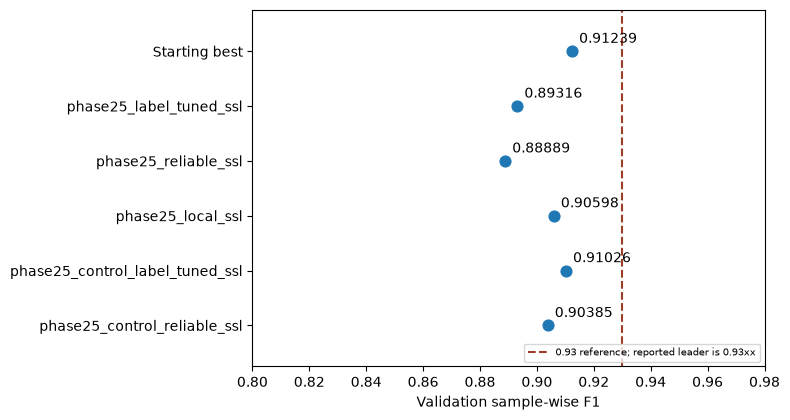

In [4]:
names=['Starting best']+table.candidate.tolist()
scores=[summary['baseline_validation_f1']]+table.validation_f1.tolist()
fig,ax=plt.subplots(figsize=(8,4.3))
y=np.arange(len(names));ax.scatter(scores,y,s=60)
for i,s in enumerate(scores):ax.annotate(f'{s:.5f}',(s,i),xytext=(5,6),textcoords='offset points')
ax.axvline(.93,color='#9b3e27',linestyle='--',label='0.93 reference; reported leader is 0.93xx')
ax.set(yticks=y,yticklabels=names,xlim=(min(.80,min(scores)-.02),max(.98,max(scores)+.02)),xlabel='Validation sample-wise F1')
ax.margins(y=.15);ax.invert_yaxis();ax.legend(loc='lower right',fontsize=7)
fig.tight_layout();fig.savefig(root/'figures/current_phase25_comparison.png',dpi=180)
plt.show()

## Reproduction and integrity

All three approaches passed uncached held-out-label perturbation tests, query-label/batch invariance, masked-duplicate exclusion and query/masked-output consistency checks. A zero local-expert blend reproduces the global model's scores. Source is embedded in notebook 04; protocols, exact model settings, OOF predictions, diagnostics and unsuccessful outcomes are under `experiments/phase25*`.

No external trial data, extra labels, ID predictors or deep learning were used. The frozen current-best configuration and its predictions are reproduced in notebook 04; raw file hashes and gold-label preservation are checked.

References: [calibration](https://scikit-learn.org/stable/modules/calibration.html), [local SVMs](https://jmlr.org/papers/v11/segata10a.html), and [SVC settings](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).

In [5]:
json.loads((root/'experiments/phase25-integrity-checks.json').read_text())

{'checks': [{'model': 'label_tuned_ssl',
   'heldout_label_invariance': True,
   'query_label_invariance': True,
   'query_batch_invariance': True,
   'unlabeled_output_consistency': True,
   'masked_duplicates_excluded': True,
   'max_label_difference': 0.0,
   'max_batch_difference': 0.0},
  {'model': 'reliable_ssl',
   'heldout_label_invariance': True,
   'query_label_invariance': True,
   'query_batch_invariance': True,
   'unlabeled_output_consistency': True,
   'masked_duplicates_excluded': True,
   'max_label_difference': 0.0,
   'max_batch_difference': 0.0},
  {'model': 'local_ssl',
   'heldout_label_invariance': True,
   'query_label_invariance': True,
   'query_batch_invariance': True,
   'unlabeled_output_consistency': True,
   'masked_duplicates_excluded': True,
   'max_label_difference': 0.0,
   'max_batch_difference': 0.0}],
 'local_zero_mix_matches_global': True,
 'caches_cleared_before_perturbation': True,
 'validation_fit': False,
 'source_sha256': {'phase25.py': 'eb6d